# 06 Sensitivity analysis
How robust are the Day 4 results, and what drives them? The backtest is rerun with one battery setting changed at a time:
- **Duration** is changed to 1, 2 (base) or 4 hours at 100 MW
- **Round-trip efficiency** is changed to 80%, 88% (base) or 95%
- **Degradation cost** is changed to \$0, \$5 (base), \$10 or \$20 per MWh discharged

Strategies: perfect foresight (upper bound), Linear (least squares) (the most profitable model) and Typical day (no forecast).

In [2]:
# Setup
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from battery import BATTERY, optimise_day, settle, day_profit
from forecasting import TEST_START, load_model_data

df = load_model_data()
test_preds = pd.read_parquet("../results/test_predictions.parquet")
test = df.loc[test_preds.index]

# Same backtest days as notebook 05: only days with all 48 periods
full_day = test.groupby("date")["tp"].transform("size") == 48
test, test_preds = test[full_day], test_preds[full_day]

# The three strategies' price forecasts, one column each
typical_day = df[df["date"] < TEST_START].groupby("tp")["price"].median()
strategies = pd.DataFrame({
    "Perfect foresight": test["price"],
    "Model 2a Linear (least squares)": test_preds["Model 2a Linear (least squares)"],
    "Typical day (no forecast)": test["tp"].map(typical_day),
})
print(f"Days in the backtest: {test['date'].nunique()}")

Days in the backtest: 353


In [4]:
def total_profits(battery):
    """Total test-year profit ($) of each strategy, for one battery setup."""
    def strategy_total(forecast):
        table = pd.DataFrame({"forecast": forecast, "actual": test["price"], "date": test["date"]})
        daily = table.groupby("date").apply(lambda d: day_profit(d["forecast"], d["actual"], battery),
                                            include_groups=False)
        return daily.sum()
    return strategies.apply(strategy_total)


def run_sensitivity(variants):
    """Run the backtest for every battery setup in `variants` (a dict of name: settings).
    Returns two tables (rows = setups, columns = strategies): profit in $m, and capture rate in %."""
    # map() runs total_profits for each setup. 
    # concat(keys=...) labels each result with its setup name
    totals = pd.concat(map(total_profits, variants.values()), axis=1, keys=variants.keys()).T / 1e6
    capture = totals.div(totals["Perfect foresight"], axis=0) * 100      # each row as a % of perfect foresight
    return totals.round(2), capture.round(1)

## 1. Duration
Power stays at 100 MW and capacity changes. The minimum reserve (10%) and start/end charge (50%) scale with capacity.

In [5]:
# BATTERY | dict(...) = a copy of the base battery with those settings replaced
DURATIONS = {
    "1 hour (100 MWh)":  BATTERY | dict(s_max=100, s_min=10, s0=50),
    "2 hours (200 MWh)": BATTERY,
    "4 hours (400 MWh)": BATTERY | dict(s_max=400, s_min=40, s0=200),
}
duration_profit, duration_capture = run_sensitivity(DURATIONS)
display(duration_profit, duration_capture)

,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
1 hour (100 MWh),6.00,1.68,1.73
2 hours (200 MWh),8.94,2.81,2.63
4 hours (400 MWh),12.07,4.00,3.66


,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
1 hour (100 MWh),100.0,28.1,28.8
2 hours (200 MWh),100.0,31.4,29.5
4 hours (400 MWh),100.0,33.1,30.3


## 2. Round-trip efficiency
Round-trip efficiency = charging efficiency × discharging efficiency, so each is set to its square root (e.g. 88% round trip = 0.94 each way).

In [7]:
EFFICIENCIES = {
    "80% round trip": BATTERY | dict(eta_c=0.80 ** 0.5, eta_d=0.80 ** 0.5),
    "88% round trip": BATTERY,
    "95% round trip": BATTERY | dict(eta_c=0.95 ** 0.5, eta_d=0.95 ** 0.5),
}
efficiency_profit, efficiency_capture = run_sensitivity(EFFICIENCIES)
display(efficiency_profit, efficiency_capture)

,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
80% round trip,7.80,1.98,1.32
88% round trip,8.94,2.81,2.63
95% round trip,10.01,3.65,3.45


,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
80% round trip,100.0,25.3,16.9
88% round trip,100.0,31.4,29.5
95% round trip,100.0,36.5,34.5


## 3. Degradation cost
The cost charged per MWh discharged, representing battery wear. Higher values make the LP skip marginal cycles.

In [8]:
DEGRADATION = {
    "$0/MWh":  BATTERY | dict(deg_cost=0),
    "$5/MWh":  BATTERY,
    "$10/MWh": BATTERY | dict(deg_cost=10),
    "$20/MWh": BATTERY | dict(deg_cost=20),
}
degradation_profit, degradation_capture = run_sensitivity(DEGRADATION)
display(degradation_profit, degradation_capture)

# Save all three analyses as two tables (profit and capture rate)
pd.concat({"Duration": duration_profit, "Efficiency": efficiency_profit,
           "Degradation cost": degradation_profit}).to_csv("../results/sensitivity_profit.csv")
pd.concat({"Duration": duration_capture, "Efficiency": efficiency_capture,
           "Degradation cost": degradation_capture}).to_csv("../results/sensitivity_capture.csv")

,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
$0/MWh,9.79,3.60,3.33
$5/MWh,8.94,2.81,2.63
$10/MWh,8.24,2.28,1.80
$20/MWh,7.09,1.40,0.88


,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
$0/MWh,100.0,36.8,34.0
$5/MWh,100.0,31.4,29.5
$10/MWh,100.0,27.7,21.8
$20/MWh,100.0,19.8,12.3


## 4. Profit by month plot
Base battery, using the daily profits saved in notebook 05.

,Perfect foresight,Model 2a Linear (least squares),Typical day (no forecast)
date,,,
07/2025,1.49,0.66,0.58
08/2025,0.65,0.10,0.07
09/2025,0.65,0.12,0.13
10/2025,0.98,0.27,0.28
11/2025,0.87,0.32,0.33
12/2025,0.45,0.06,0.11
01/2026,0.11,-0.03,-0.02
02/2026,0.70,0.22,0.23
03/2026,0.67,0.15,0.11


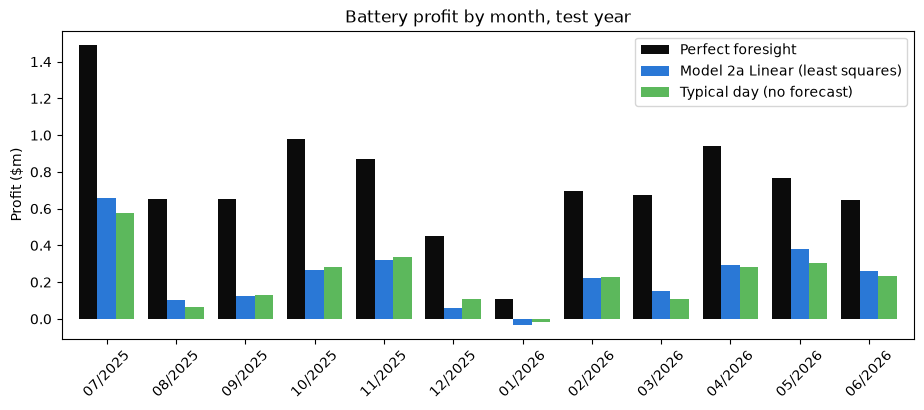

In [9]:
BLUE, GREEN, BLACK = "#2a78d6", "#5cb85c", "#0b0b0b"

daily = pd.read_parquet("../results/battery_daily_profits.parquet")       # from notebook 05
shown = ["Perfect foresight", "Model 2a Linear (least squares)", "Typical day (no forecast)"]

# Sum each strategy's daily profits by month, in $m
monthly = daily[shown].groupby(daily.index.to_period("M")).sum() / 1e6
monthly.index = monthly.index.strftime("%m/%Y")

fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot.bar(ax=ax, color=[BLACK, BLUE, GREEN], width=0.8)     # grouped bars, one group per month
ax.set_title("Battery profit by month, test year")
ax.set_ylabel("Profit ($m)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=45)
fig.savefig("../results/figures/09_monthly_profit.png", dpi=150, bbox_inches="tight")
monthly.round(2)

## 5. Why do naive forecasts do so badly?
The naive schedule on the day after the test year's biggest spike. If the explanation is right, it expects yesterday's spike to repeat.

Naive profit on 22/07/2025: $30,545
Perfect-foresight profit that day: $48,460


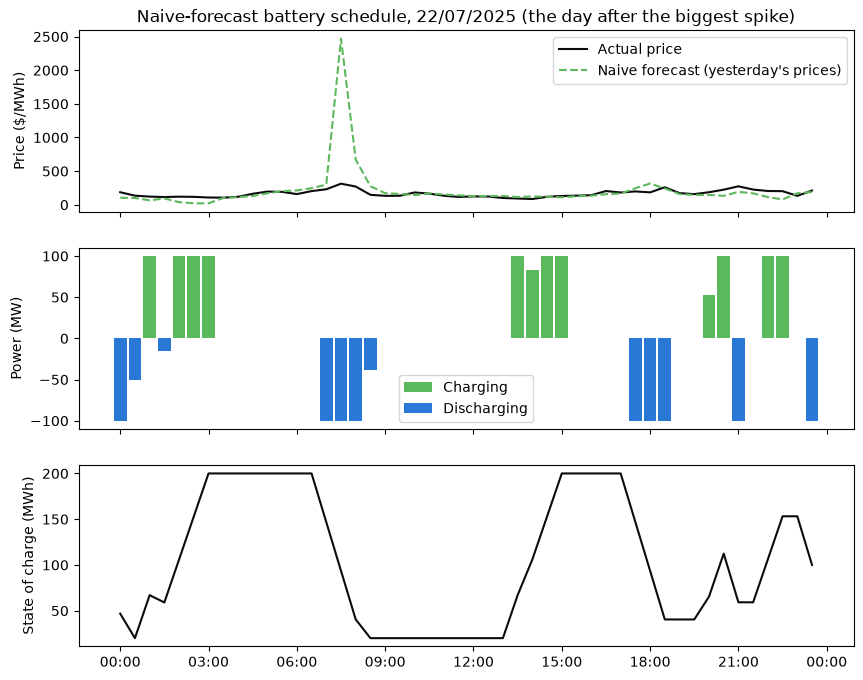

In [ ]:
SPIKE_DAY = daily["Perfect foresight"].idxmax()        # the most profitable day (21/07/2025)
DAY = SPIKE_DAY + pd.Timedelta(days=1)                 # the day after it
day = test[test["date"] == DAY]

# Plan the day with the naive forecast (= yesterday's prices), as the backtest did
naive_forecast = test_preds.loc[day.index, "Model 0 Naive (yesterday)"]
charge, discharge, soc = optimise_day(naive_forecast)
print(f"Naive profit on {DAY.strftime('%d/%m/%Y')}: ${settle(charge, discharge, day['price']):,.0f}")
print(f"Perfect-foresight profit that day: ${daily.loc[DAY, 'Perfect foresight']:,.0f}")

times = day["time_nz"]
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax1.plot(times, day["price"], color=BLACK, linewidth=1.5, label="Actual price")
ax1.plot(times, naive_forecast, color=GREEN, linestyle="--", linewidth=1.5, label="Naive forecast (yesterday's prices)")
ax1.set_ylabel("Price ($/MWh)")
ax1.set_title(f"Naive-forecast battery schedule, {DAY.strftime('%d/%m/%Y')} (the day after the biggest spike)")
ax1.legend()

ax2.bar(times, charge, width=0.018, color=GREEN, label="Charging")
ax2.bar(times, -discharge, width=0.018, color=BLUE, label="Discharging")
ax2.set_ylabel("Power (MW)")
ax2.legend()

ax3.plot(times, soc, color=BLACK, linewidth=1.5)
ax3.set_ylabel("State of charge (MWh)")
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=times.dt.tz))
fig.savefig("../results/figures/10_naive_day_after_spike.png", dpi=150, bbox_inches="tight")

In [11]:
# Where does the naive strategy lose its money?
naive_daily = daily["Model 0 Naive (yesterday)"]
print(f"Days with a loss: {(naive_daily < 0).sum()} of {len(naive_daily)}")
print(f"Total lost on those days: ${-naive_daily[naive_daily < 0].sum() / 1e6:.2f}m")

# The 5 worst days, with what perfect foresight earned on the same days
worst = pd.DataFrame({"Naive profit ($)": naive_daily.nsmallest(5),
                      "Perfect foresight ($)": daily.loc[naive_daily.nsmallest(5).index, "Perfect foresight"]})
worst.index = worst.index.strftime("%d/%m/%Y")
worst.round(0)

Days with a loss: 152 of 353
Total lost on those days: $0.91m


,Naive profit ($),Perfect foresight ($)
date,,
23/10/2025,-53968.0,104156.0
11/07/2025,-45628.0,74506.0
03/07/2025,-27137.0,75196.0
01/08/2025,-25675.0,16896.0
02/08/2025,-22794.0,27692.0


### Naive's worst day
23/10/2025: naive lost \$54k while perfect foresight earned \$104k. What went wrong?

Naive profit on 23/10/2025: $-53,968
Perfect-foresight profit that day: $104,156


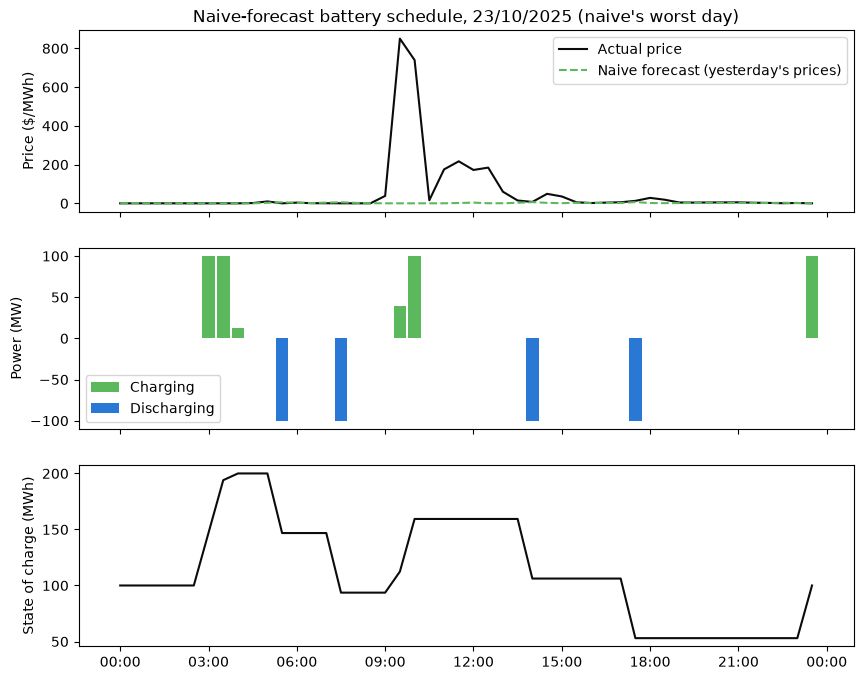

In [15]:
DAY = pd.Timestamp("2025-10-23")                       # naive's worst day of the test year
day = test[test["date"] == DAY]

# Plan the day with the naive forecast (= yesterday's prices), as the backtest did
naive_forecast = test_preds.loc[day.index, "Model 0 Naive (yesterday)"]
charge, discharge, soc = optimise_day(naive_forecast)
print(f"Naive profit on {DAY.strftime('%d/%m/%Y')}: ${settle(charge, discharge, day['price']):,.0f}")
print(f"Perfect-foresight profit that day: ${daily.loc[DAY, 'Perfect foresight']:,.0f}")

times = day["time_nz"]
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax1.plot(times, day["price"], color=BLACK, linewidth=1.5, label="Actual price")
ax1.plot(times, naive_forecast, color=GREEN, linestyle="--", linewidth=1.5, label="Naive forecast (yesterday's prices)")
ax1.set_ylabel("Price ($/MWh)")
ax1.set_title(f"Naive-forecast battery schedule, {DAY.strftime('%d/%m/%Y')} (naive's worst day)")
ax1.legend()

ax2.bar(times, charge, width=0.018, color=GREEN, label="Charging")
ax2.bar(times, -discharge, width=0.018, color=BLUE, label="Discharging")
ax2.set_ylabel("Power (MW)")
ax2.legend()

ax3.plot(times, soc, color=BLACK, linewidth=1.5)
ax3.set_ylabel("State of charge (MWh)")
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=times.dt.tz))
fig.savefig("../results/figures/11_naive_worst_day.png", dpi=150, bbox_inches="tight")

## What are the key findings?
1. **Longer batteries earn more, with diminishing returns.** Perfect-foresight profit per MWh of capacity falls from \$60k (1 hour) to \$45k (2 hours) to \$30k (4 hours). Forecasts capture more with longer batteries (28.1% to 33.1%) because exact peak timing matters less.
2. **The value of forecasting grows when cycling is costly or lossy.** At 80% round-trip efficiency the typical-day schedule's capture falls to 16.9% while the linear model holds 25.3%. At a \$20/MWh degradation cost the linear model earns 59% more than the typical day (\$1.40m vs \$0.88m). The near-tie between them on Day 4 is specific to the base battery.
3. **Efficiency is high-leverage:** moving from 88% to 95% round trip raises the linear strategy's profit by \$0.84m (+30%).
4. **Value is concentrated in time:** July 2025 alone produced 17% of the year's perfect-foresight profit, while January 2026 (prices near \$0) made a small loss for both forecast strategies.
5. **Naive forecasts lose money on 43% of days** (152 of 353, \$0.91m in total). On its worst day, 23/10/2025, yesterday's prices were flat near \$0, so the naive plan's timing was effectively arbitrary: it charged at 09:30 to 10:00, exactly when the real price spiked to about \$850/MWh, losing \$54k while perfect foresight earned \$104k. When yesterday happens to resemble today it does fine (e.g. 22/07/2025: 63% capture).
6. **Trading on near-flat forecasts is mostly noise.** Both naive's worst day and January 2026's losses come from days with tiny forecast spreads. A rule to skip trading when the forecast spread is below a threshold is a natural next improvement.